# Question 3 — Weak duality and the lower envelope
**EN3330 — Introduction to Engineering Optimization, Assignment 03**

We prove weak duality for a general inequality-constrained problem and use the specific example from Question 1 to examine concavity of the dual function.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (7.1, 3.7),
    'figure.dpi': 140,
    'savefig.dpi': 250,
    'font.size': 10.5,
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.linewidth': .55,
    'grid.alpha': .24,
    'lines.linewidth': 1.9,
    'legend.fontsize': 9,
})

def format_ax(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, axis='both', zorder=0)
    ax.set_axisbelow(True)

## 3(a) — Why the dual value is a lower bound
Consider

$$\min_x f(x)\quad\text{subject to}\quad h(x)\leq0,$$

with $L(\mu,x)=f(x)+\mu h(x)$, $\mu\geq0$, and $d(\mu)=\inf_x L(\mu,x)$.

For any feasible $x$ and nonnegative $\mu$,

$$\underbrace{d(\mu)\leq L(\mu,x)}_{\text{minimum over all }x}
=f(x)+\mu h(x)\ \underbrace{\leq f(x)}_{\mu h(x)\leq0}.$$

- The first inequality holds because the infimum cannot exceed the value at a specific $x$.
- The second holds because $h(x)\leq0$ and $\mu\geq0$.

This is true at every feasible point, including the optimum. Therefore

$$\boxed{d(\mu)\leq p^*\qquad\text{for every }\mu\geq0.}$$

For Question 1, $p^*=1$ and $d(\mu)=\mu-\mu^2/4$. Evaluate the specified multipliers $\mu=0,1,2,3$.

In [2]:
def dual(mu):
    return mu - mu**2/4

p_star = 1.0
for mu in (0, 1, 2, 3):
    value = dual(mu)
    print(f"mu={mu}: d(mu)={value:.2f} <= p*={p_star:.2f}, gap={p_star-value:.2f}")
    assert value <= p_star + 1e-12

mu=0: d(mu)=0.00 <= p*=1.00, gap=1.00
mu=1: d(mu)=0.75 <= p*=1.00, gap=0.25
mu=2: d(mu)=1.00 <= p*=1.00, gap=0.00
mu=3: d(mu)=0.75 <= p*=1.00, gap=0.25


## 3(b) — Lines at three fixed values of $x$
For the same $L(\mu,x)=x^2+\mu(1-x)$, select $x=0$, $1$, and $2$:

$$\begin{aligned}
L(\mu,0)&=\mu,\\
L(\mu,1)&=1,\\
L(\mu,2)&=4-\mu.
\end{aligned}$$

Their **lower envelope** is the minimum of these three lines, at each $\mu$:

$$\tilde d(\mu)=\min\{\mu,1,4-\mu\}
=\begin{cases}
\mu,&0\leq\mu\leq1,\\
1,&1\leq\mu\leq3,\\
4-\mu,&\mu\geq3.
\end{cases}$$

The exact dual $d(\mu)=\min_{x\in\mathbb R}L(\mu,x)$ minimizes over *all* $x$, so $d(\mu)\leq\tilde d(\mu)$. Thus the finite-sample lower envelope is an **upper approximation to the exact dual**, not a lower bound on it.

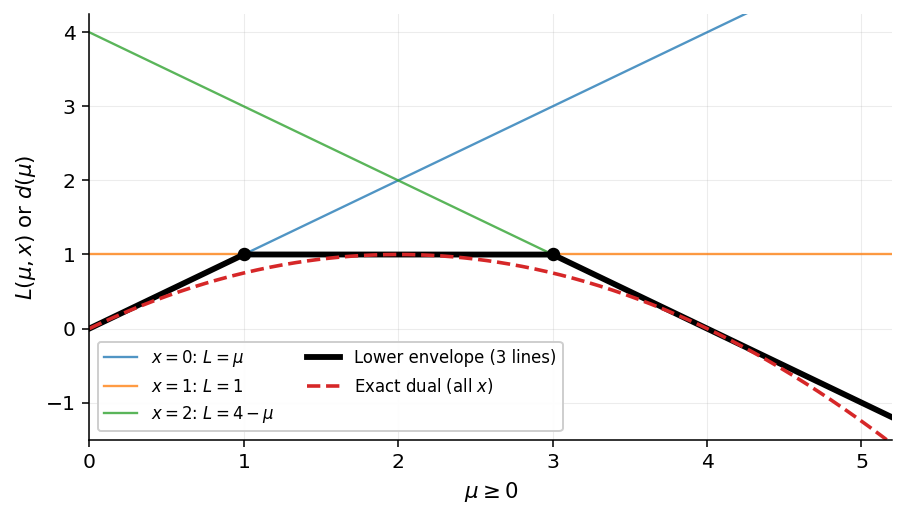

In [3]:
# Figure 6: lower envelope of three selected affine functions (and exact dual)
fig,ax=plt.subplots(figsize=(7.4,3.95))
mm=np.linspace(0,5.2,500)
y0=mm
y1=np.ones_like(mm)
y2=4-mm
env=np.minimum.reduce([y0,y1,y2])
ax.plot(mm,y0,lw=1.2,alpha=.78,label=r'$x=0$: $L=\mu$')
ax.plot(mm,y1,lw=1.2,alpha=.78,label=r'$x=1$: $L=1$')
ax.plot(mm,y2,lw=1.2,alpha=.78,label=r'$x=2$: $L=4-\mu$')
ax.plot(mm,env,lw=3,c='black',label='Lower envelope (3 lines)')
ax.plot(mm,mm-mm*mm/4,linestyle='--',lw=1.85,label='Exact dual (all $x$)')
ax.scatter([1,3],[1,1],s=35,c='black',zorder=5)
ax.set_xlim(0,5.2);ax.set_ylim(-1.5,4.25)
format_ax(ax,r'$\mu\geq0$',r'$L(\mu,x)$ or $d(\mu)$')
ax.legend(ncol=2,loc='lower left',framealpha=.95,fontsize=8.5)
fig.savefig(FIG_DIR/'06_affine_lines_envelope.png', bbox_inches='tight', pad_inches=.15)
plt.show()

### Why the dual function is concave — even if $f$ is non-convex
For any fixed $x$, $L(\mu,x)=f(x)+\mu h(x)$ is an **affine function** of $\mu$. The dual function is the pointwise infimum of all such lines. A pointwise infimum of affine functions is concave; convexity of $f$ was never needed.

To see this algebraically, for $\mu_1,\mu_2\geq0$ and $\theta\in[0,1]$:

$$\begin{aligned}
d(\theta\mu_1+(1-\theta)\mu_2)
&=\inf_x\big[\theta L(\mu_1,x)+(1-\theta)L(\mu_2,x)\big]\\
&\geq\theta\inf_x L(\mu_1,x)+(1-\theta)\inf_x L(\mu_2,x)\\
&=\theta d(\mu_1)+(1-\theta)d(\mu_2).
\end{aligned}$$

This is the definition of concavity. The three-line lower envelope is a visual example of the same property.

In [4]:
# Optional numerical check of the concavity inequality for the exact dual.
rng = np.random.default_rng(3330)
mu1 = rng.uniform(0, 5, 200)
mu2 = rng.uniform(0, 5, 200)
theta = rng.uniform(0, 1, 200)
lhs = dual(theta*mu1 + (1-theta)*mu2)
rhs = theta*dual(mu1) + (1-theta)*dual(mu2)
assert np.all(lhs >= rhs - 1e-12)
print("Concavity verified on 200 randomly selected triples (illustrative numerical check).")

Concavity verified on 200 randomly selected triples (illustrative numerical check).


**Conclusion.** Weak duality guarantees that $d(\mu)$ never exceeds the primal optimum. The dual function is concave because it is the minimum over a family of straight lines in $\mu$, regardless of whether the original objective $f$ is convex.